In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/imshalimran/raw-dataset-of-students-applying-eda/student_data.csv


# Assignment No. 3: Exploratory Data Analysis (EDA)

## 1. Dataset Introduction

The Student Performance Dataset contains information about students' demographic backgrounds, family circumstances, study habits, school support, absences, and academic grades.

The purpose of this EDA is to understand the distribution of individual features, examine relationships between variables, identify unusual observations, and discover patterns related to students' final grades.

- **Dataset:** Student Performance Dataset
- **Source:** Kaggle
- **Dataset link:** https://www.kaggle.com/datasets/devansodariya/student-performance-data
- **Target variable:** `G3` (final grade)
- **Problem statement:** Which student characteristics and academic factors are associated with final academic performance?

In [2]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.endswith(".csv"):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/imshalimran/raw-dataset-of-students-applying-eda/student_data.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/kaggle/input/datasets/imshalimran/raw-dataset-of-students-applying-eda/student_data.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


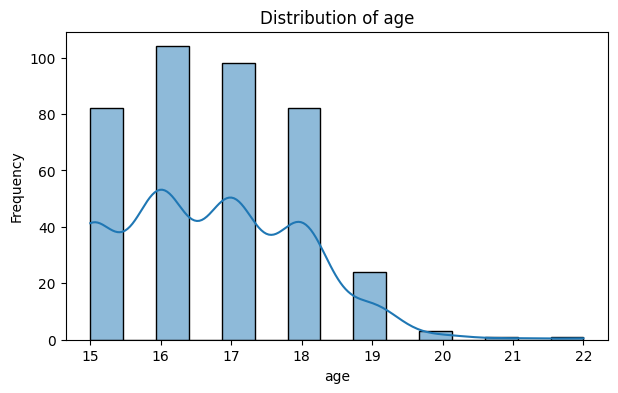

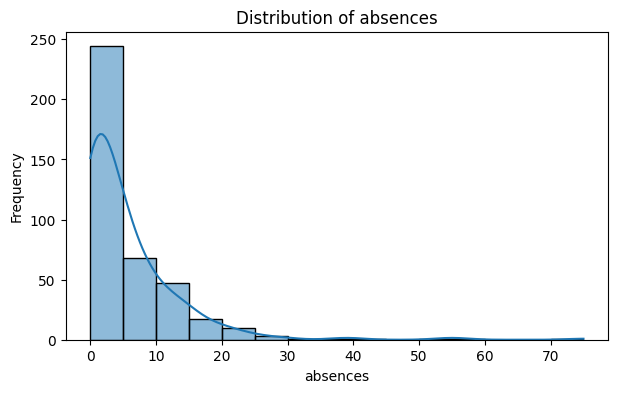

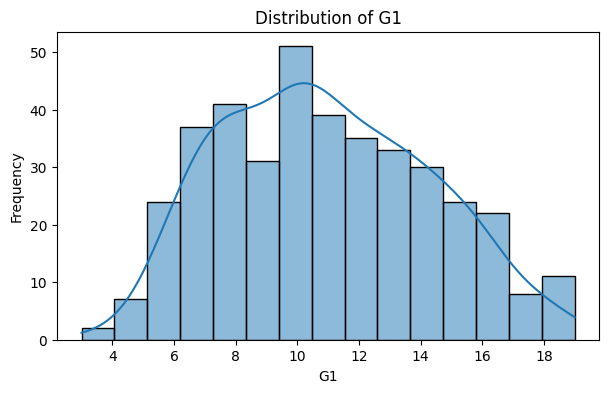

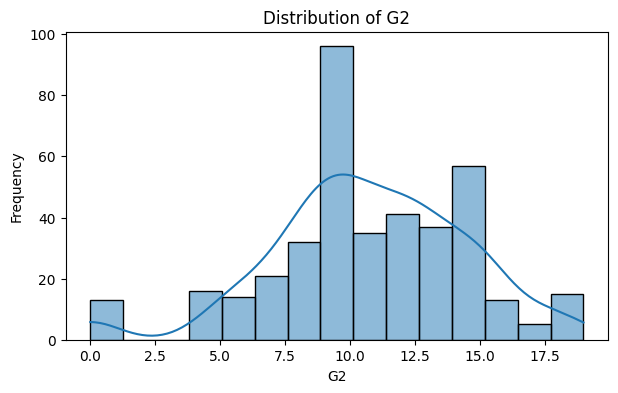

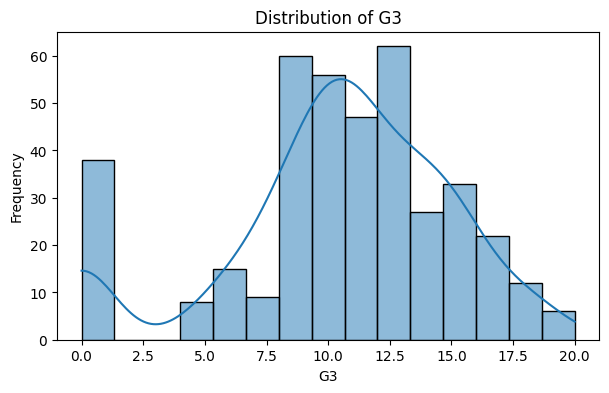

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = ['age', 'absences', 'G1', 'G2', 'G3']

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True, bins=15)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

## 2. Univariate Exploratory Data Analysis

Univariate EDA involves analyzing one variable at a time to understand its distribution, frequency, and spread. Histograms and density curves are used to identify common values, skewness, and possible patterns in numerical features. In this analysis, we explore `age`, `absences`, `G1`, `G2`, and `G3` to understand students' ages, absences, and grades.## 2. Univariate Exploratory Data Analysis

Univariate EDA involves analyzing one variable at a time to understand its distribution, frequency, and spread. Histograms and density curves are used to identify common values, skewness, and possible patterns in numerical features. In this analysis, we explore `age`, `absences`, `G1`, `G2`, and `G3` to understand students' ages, absences, and grades.

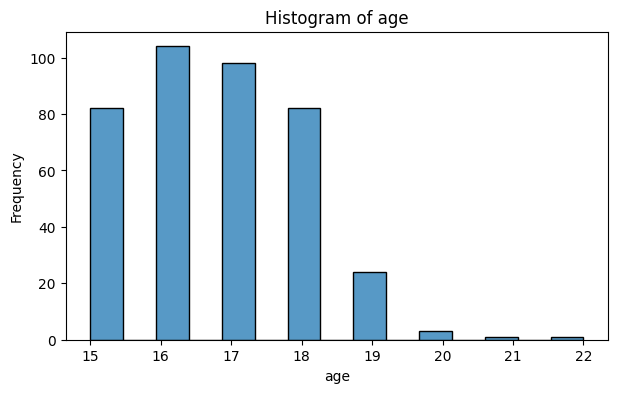

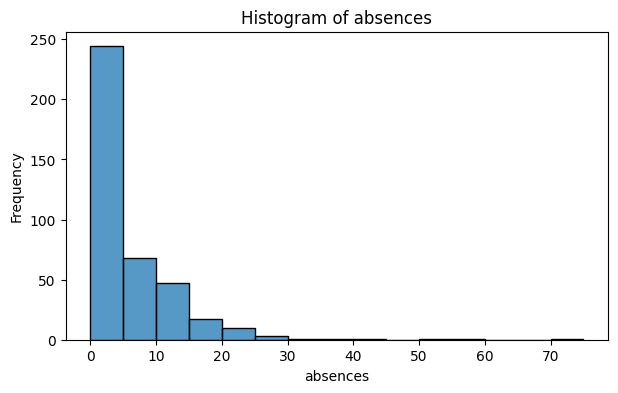

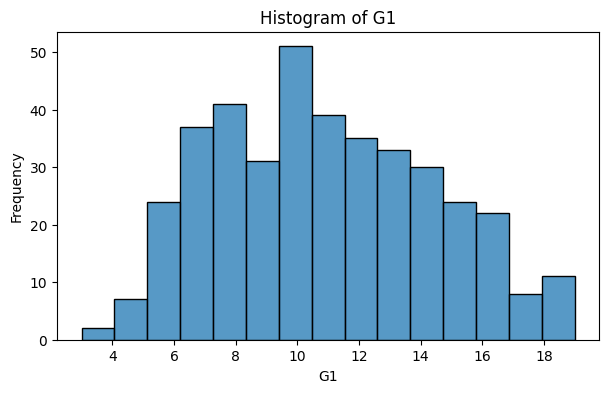

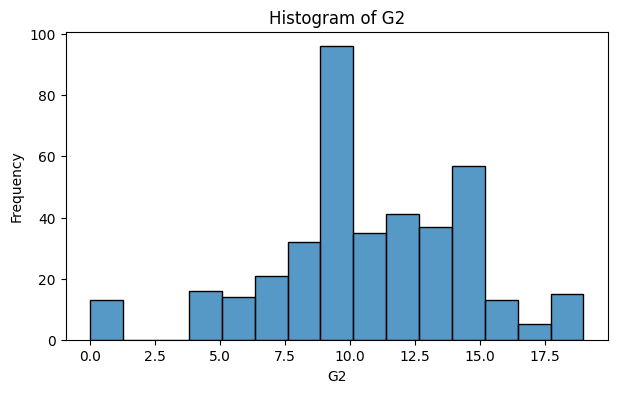

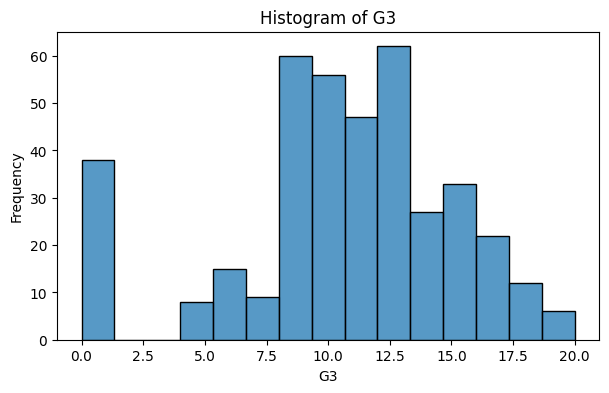

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = ['age', 'absences', 'G1', 'G2', 'G3']

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, bins=15)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

### Histogram Analysis

Histograms show the frequency distribution of numerical variables. They help us understand how values are distributed and identify common ranges, spread, and possible skewness. In this dataset, we examine students' ages, absences, and grades (`G1`, `G2`, and `G3`). The graphs help us understand the distribution of these features.

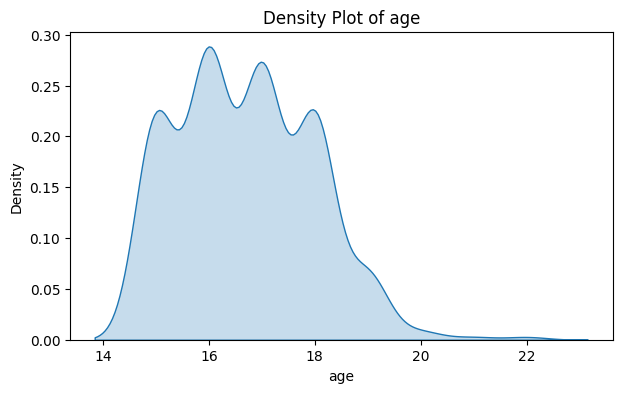

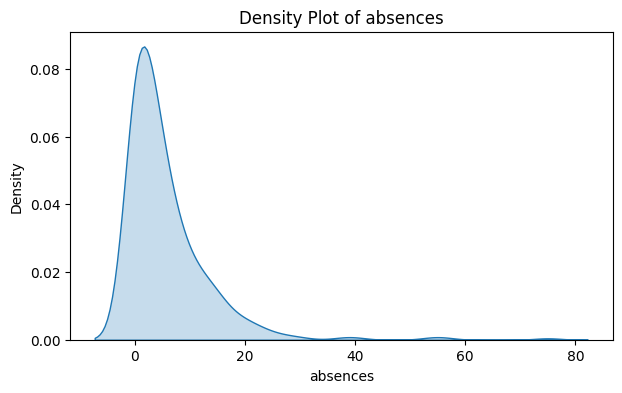

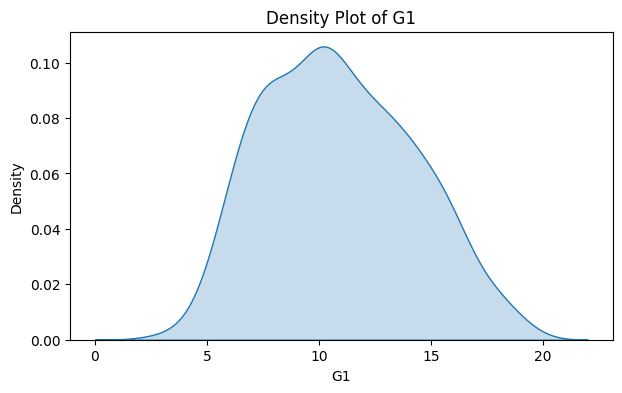

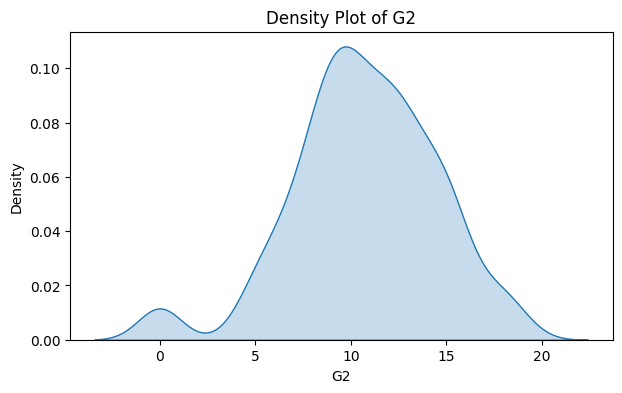

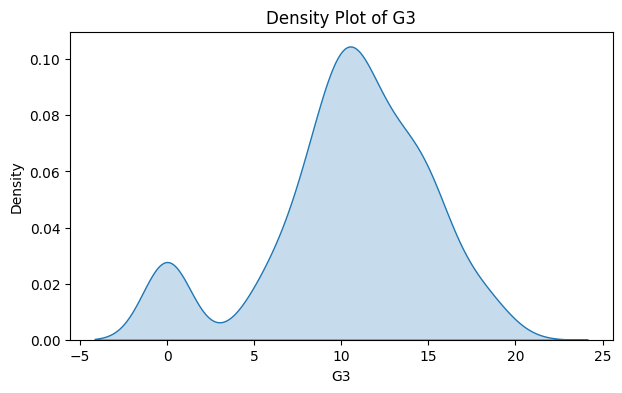

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = ['age', 'absences', 'G1', 'G2', 'G3']

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(data=df, x=col, fill=True)
    plt.title(f'Density Plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Density')
    plt.show()

### Density Plot Analysis

Density plots show the distribution of numerical variables using a smooth curve. The peaks indicate where values are more concentrated, while the shape helps identify skewness and spread. In this dataset, density plots help us understand the distributions of students' ages, absences, and grades (`G1`, `G2`, and `G3`).

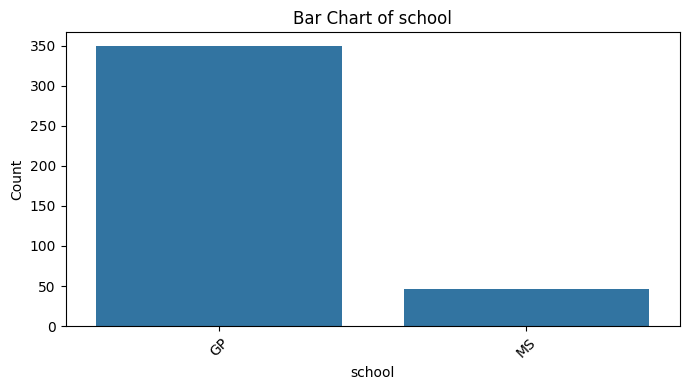

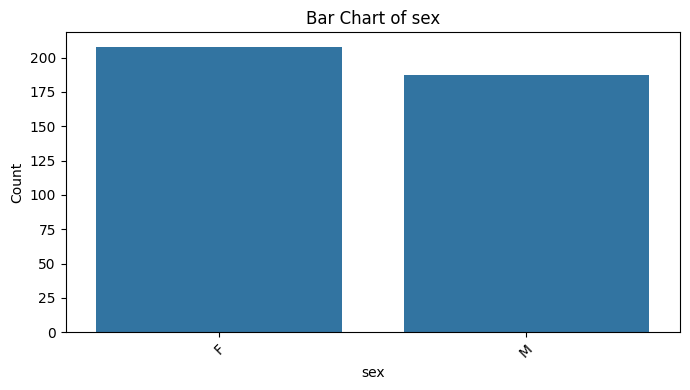

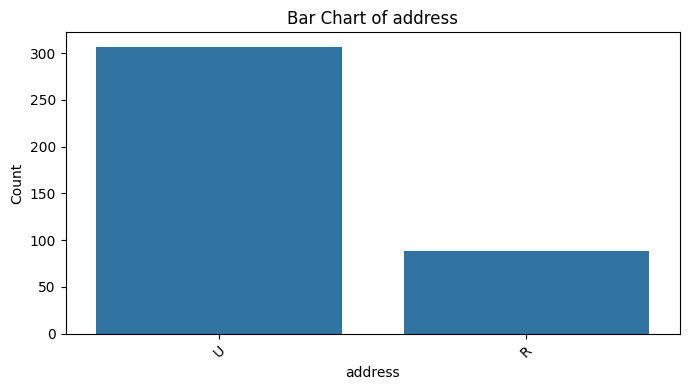

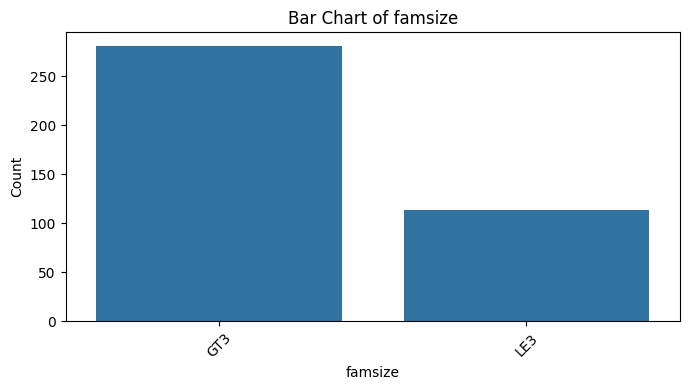

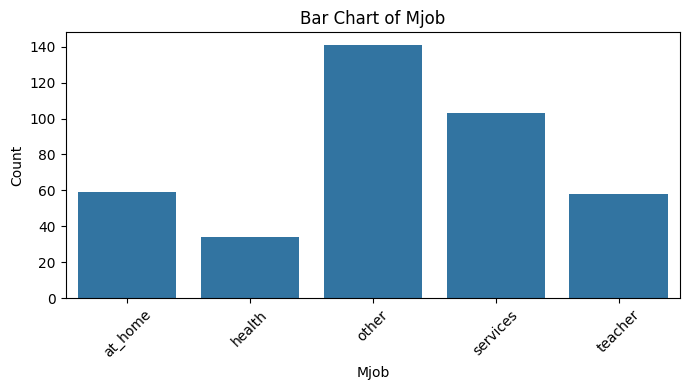

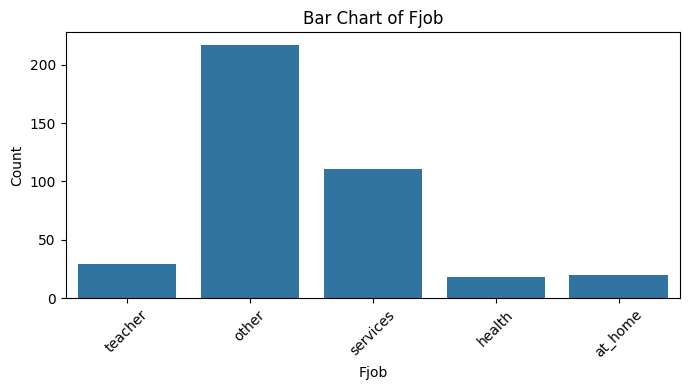

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

categorical_features = ['school', 'sex', 'address', 'famsize', 'Mjob', 'Fjob']

for col in categorical_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Bar Chart of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Bar Chart Analysis

Bar charts show the frequency of each category in a categorical variable. They help us compare category sizes and identify the most and least common categories. In this dataset, we examine variables such as school, sex, address, family size, and parents' jobs to understand the distribution of students across different categories.

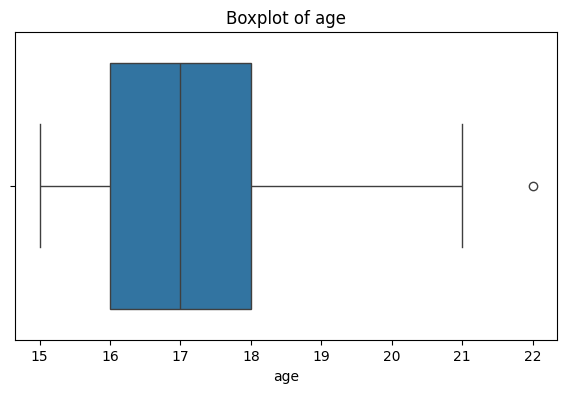

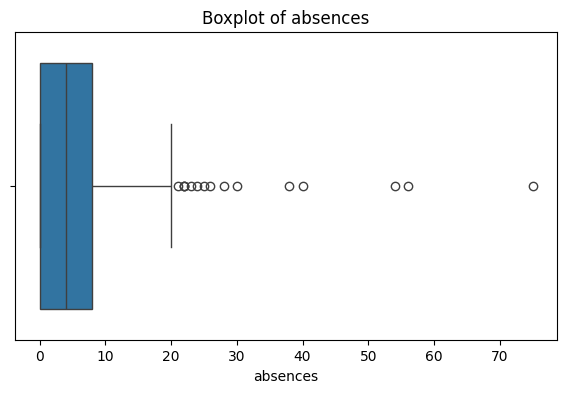

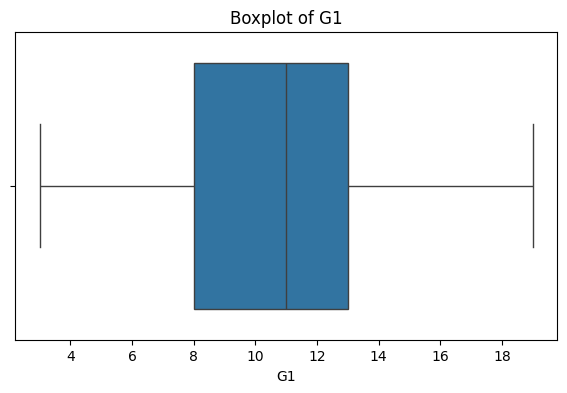

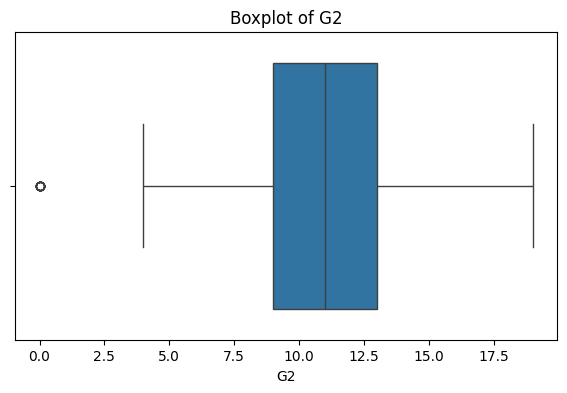

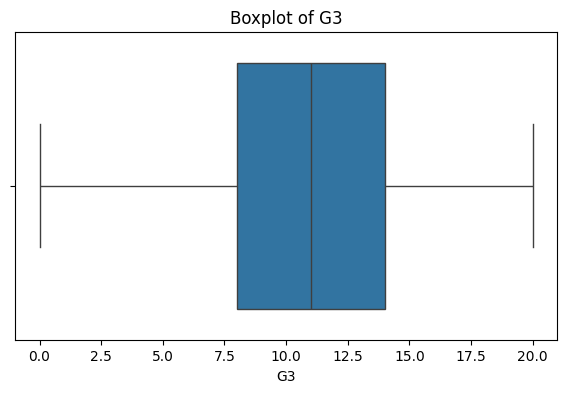

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = ['age', 'absences', 'G1', 'G2', 'G3']

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=col)
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

### Boxplot Analysis

Boxplots display the median, quartiles, and spread of numerical variables. They help identify variability and potential outliers, which appear as individual points beyond the whiskers. In this dataset, boxplots of age, absences, and grades (`G1`, `G2`, and `G3`) help us examine the spread of values and identify unusual observations that may require further investigation.

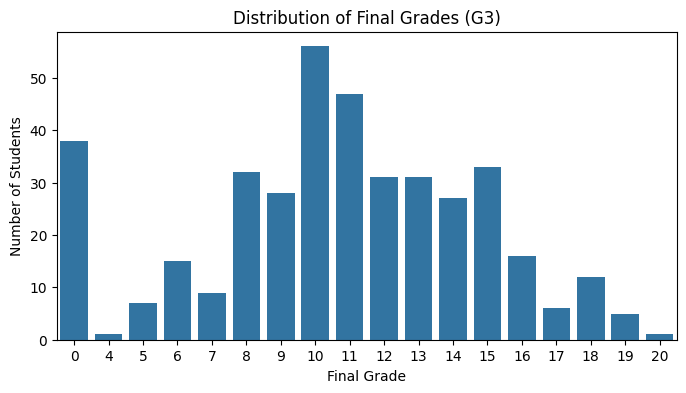

Number of unique grades: 18

Frequency of each grade:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='G3')
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.show()

print("Number of unique grades:", df['G3'].nunique())
print("\nFrequency of each grade:")
print(df['G3'].value_counts().sort_index())

## 3. Target Analysis

The target variable is `G3`, which represents students' final grades.

- **Distribution:** The count plot displays the number of students receiving each final grade.
- **Balance:** The target distribution is assessed by comparing the frequency of different grades. If some grades occur much more frequently than others, the distribution is uneven.
- **Observation:** The graph helps identify common and rare final grades. Since `G3` is a numerical variable, uneven frequencies do not automatically mean a classification target is imbalanced. Class imbalance is more relevant if grades are grouped into categories.

These observations can help determine whether the target needs any special consideration during future modeling.

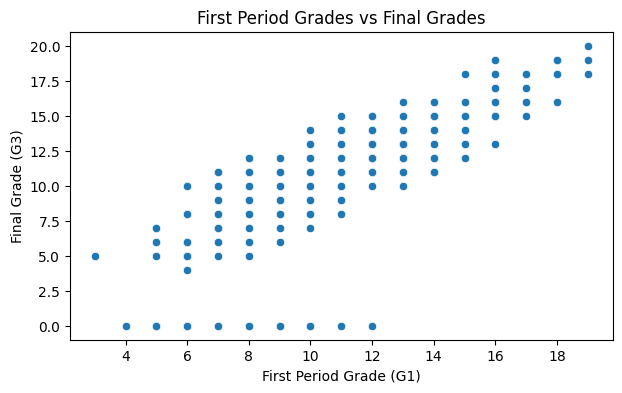

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='G1', y='G3')
plt.title('First Period Grades vs Final Grades')
plt.xlabel('First Period Grade (G1)')
plt.ylabel('Final Grade (G3)')
plt.show()

## 4. Bivariate Exploratory Data Analysis

### 4.1 Scatter Plot: G1 vs G3

The scatter plot examines the relationship between first-period grades (`G1`) and final grades (`G3`). Each point represents a student. The pattern of points helps us understand whether students with higher first-period grades tend to achieve higher final grades. An upward trend suggests a positive relationship between the two variables.

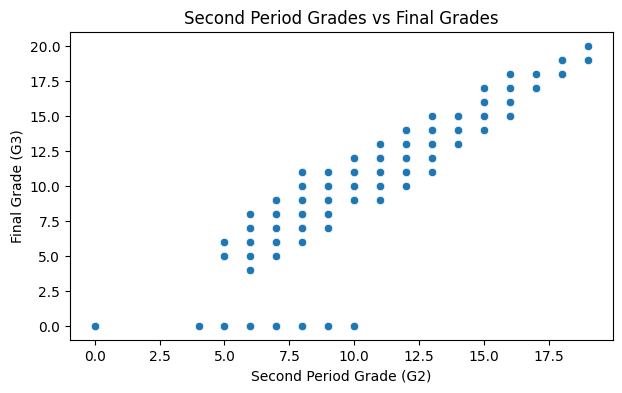

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='G2', y='G3')
plt.title('Second Period Grades vs Final Grades')
plt.xlabel('Second Period Grade (G2)')
plt.ylabel('Final Grade (G3)')
plt.show()

### 4.2 Feature vs Target: G2 vs G3

The scatter plot compares second-period grades (`G2`) with final grades (`G3`). Each point represents a student. An upward pattern indicates that students with higher second-period grades tend to achieve higher final grades. This relationship may help identify useful features for predicting final grades in future modeling.

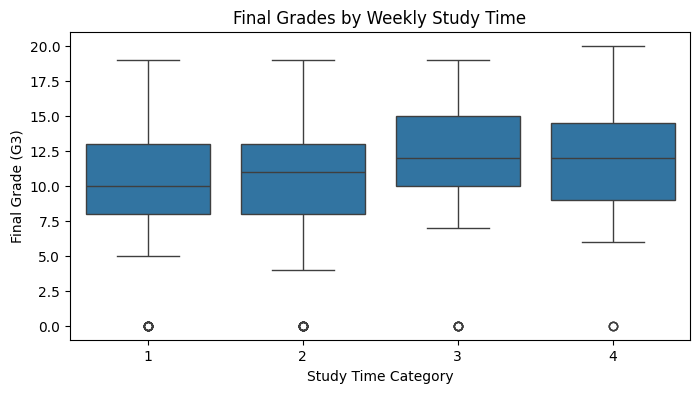

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='studytime', y='G3')
plt.title('Final Grades by Weekly Study Time')
plt.xlabel('Study Time Category')
plt.ylabel('Final Grade (G3)')
plt.show()

### 4.3 Boxplot by Category: Study Time vs Final Grade

The boxplot compares students' final grades across different study-time categories. Each box shows the median, quartiles, and spread of grades within a category. Comparing these distributions helps us explore whether students with different weekly study times tend to achieve different final grades. The graph shows an association, not necessarily a cause-and-effect relationship.

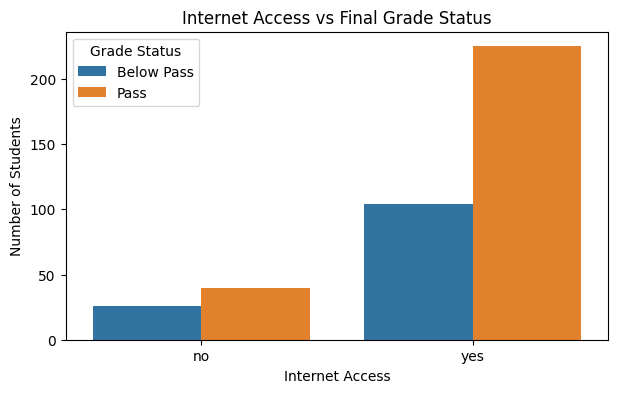

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df['grade_status'] = df['G3'].apply(
    lambda grade: 'Pass' if grade >= 10 else 'Below Pass'
)

plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    x='internet',
    hue='grade_status'
)
plt.title('Internet Access vs Final Grade Status')
plt.xlabel('Internet Access')
plt.ylabel('Number of Students')
plt.legend(title='Grade Status')
plt.show()

### 4.4 Grouped Bar Chart: Internet Access vs Grade Status

The grouped bar chart compares students' internet access with their final grade status. For this analysis, grades of 10 or above are classified as Pass, while grades below 10 are classified as Below Pass. The chart helps compare the number of students in each grade category among those with and without internet access. The observed differences may suggest an association, but they do not prove that internet access causes better grades.

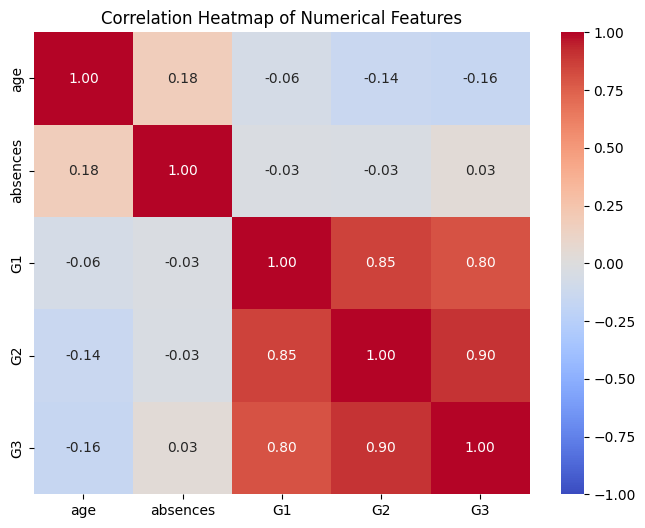

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = ['age', 'absences', 'G1', 'G2', 'G3']

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

## 5. Correlation Analysis

A correlation heatmap shows the strength and direction of relationships between numerical variables. Correlation values range from -1 to +1.

- **Strong positive correlation:** Values close to +1 indicate that two variables tend to increase together.
- **Strong negative correlation:** Values close to -1 indicate that one variable tends to decrease as the other increases.
- **Weak correlation:** Values close to 0 indicate a weak linear relationship.

The heatmap helps identify relationships among age, absences, first-period grades (`G1`), second-period grades (`G2`), and final grades (`G3`). The actual correlation values should be examined to identify the strongest and weakest relationships. Correlation does not necessarily imply causation.

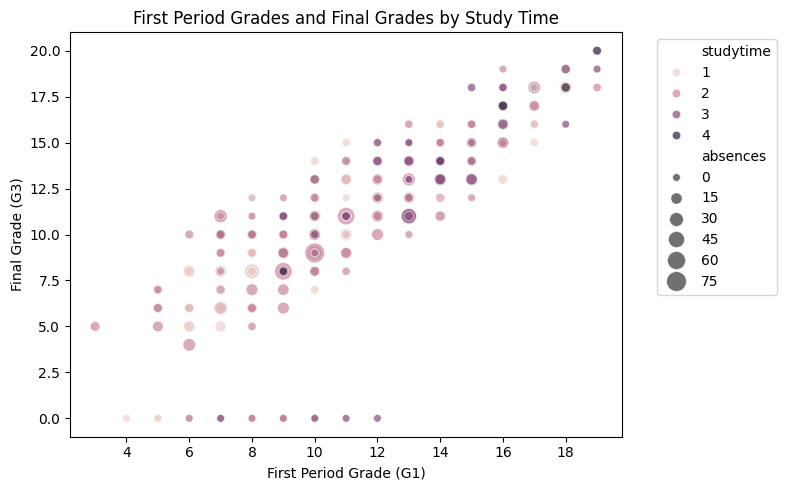

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='G1',
    y='G3',
    hue='studytime',
    size='absences',
    sizes=(30, 200),
    alpha=0.7
)

plt.title('First Period Grades and Final Grades by Study Time')
plt.xlabel('First Period Grade (G1)')
plt.ylabel('Final Grade (G3)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Multivariate Exploratory Data Analysis

This scatter plot examines multiple variables together. It compares first-period grades (`G1`) with final grades (`G3`), uses color to represent weekly study time (`studytime`), and uses point size to represent absences (`absences`).

The visualization helps explore whether students' grades vary with study time and whether students with more absences show different grade patterns. These combined relationships may help identify useful features for future modeling. The graph shows associations, not necessarily cause-and-effect relationships.

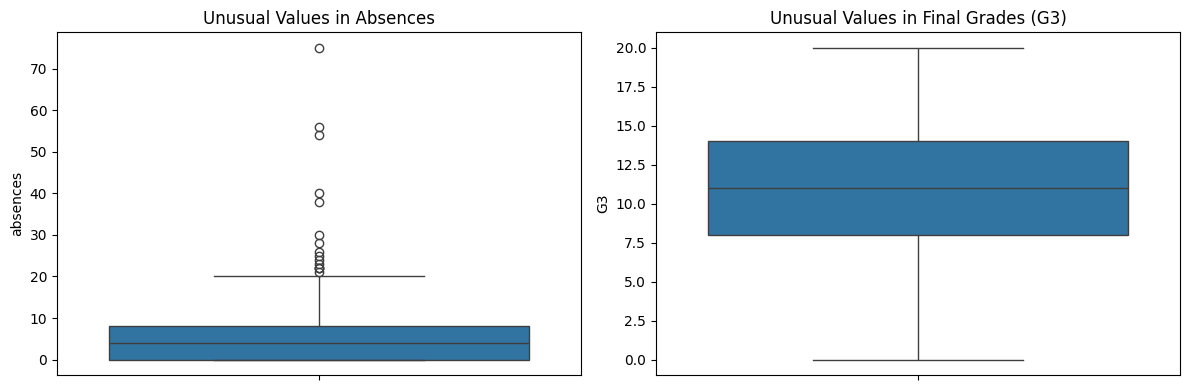

Upper bound for absences: 20.0

Students with unusually high absences:
     absences  G1  G2  G3
40         25   7  10  11
74         54  11  12  11
103        26   7   6   6
183        56   9   9   8
198        24  18  18  18
205        28  10   9   9
216        22   6   6   4
260        21  17  18  18
276        75  10   9   9
277        22   9   9   9
280        30   8   8   8
307        38   8   9   8
313        22  13  10  11
315        40  13  11  11
320        23  13  13  13


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check unusual values in absences and final grades
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, y='absences', ax=axes[0])
axes[0].set_title('Unusual Values in Absences')

sns.boxplot(data=df, y='G3', ax=axes[1])
axes[1].set_title('Unusual Values in Final Grades (G3)')

plt.tight_layout()
plt.show()

# Display students with unusually high absences
Q1 = df['absences'].quantile(0.25)
Q3 = df['absences'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

print("Upper bound for absences:", upper_bound)
print("\nStudents with unusually high absences:")
print(df[df['absences'] > upper_bound][['absences', 'G1', 'G2', 'G3']])

## 7. Patterns, Trends, and Anomalies

Boxplots are used to identify potential unusual observations in students' absences and final grades. The Interquartile Range (IQR) method identifies values outside the expected range.

Students with unusually high absences may represent observations that require further investigation. These values are not necessarily errors and should not be removed without a valid reason. Comparing absences with grades can also help explore patterns that may be useful for future modeling.

## 8. Final Findings

The Exploratory Data Analysis of the Student Performance Dataset provided useful insights into students' grades, study habits, and absences.

1. **Grade Distribution:** The distributions of `G1`, `G2`, and `G3` help us understand students' academic performance and identify common grade ranges.

2. **Grade Relationship:** Comparing `G1`, `G2`, and `G3` helps explore how grades from earlier periods relate to final grades.

3. **Study Time:** Comparing study time with final grades helps investigate whether students with different study habits show different academic outcomes.

4. **Absences:** The distribution of `absences` helps identify students with unusually high absences who may require further investigation.

5. **Categorical Features:** Bar charts reveal the frequency of categories such as school, sex, address, and parents' occupations.

6. **Correlation:** The correlation heatmap helps identify numerical features that have stronger or weaker relationships with the final grade.

7. **Combined Patterns:** Multivariate analysis helps explore how grades, study time, and absences vary together.

8. **Future Modeling:** These findings can help select relevant features, identify unusual observations, and guide the development of a model to predict students' final grades.

Overall, EDA provides a better understanding of the dataset and helps guide future data preprocessing and predictive modeling.